# Import Library

Library yang akan digunakan:
- `pandas` untuk membaca dan mengolah data
- `numpy` untuk operasi numerik
- `matplotlib` untuk visualisasi
- `scikit-learn` untuk pembagian data, preprocessing, model, dan evaluasi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)

## Bagian 1 - EDA

### Membaca Dataset

In [2]:
df = pd.read_csv("dataset/creditcard.csv", low_memory=False)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,...,1.190739,-1.127670,-2.358579,0.673461,-1.413700,-0.462762,-2.018575,-1.042804,364.19,1
1,44261.0,0.339812,-2.743745,-0.134070,-1.385729,-1.451413,1.015887,-0.524379,0.224060,0.899746,...,-0.213436,-0.942525,-0.526819,-1.156992,0.311211,-0.746647,0.040996,0.102038,520.12,0
2,35484.0,1.399590,-0.590701,0.168619,-1.029950,-0.539806,0.040444,-0.712567,0.002299,-0.971747,...,0.102398,0.168269,-0.166639,-0.810250,0.505083,-0.232340,0.011409,0.004634,31.00,0
3,167123.0,-0.432071,1.647895,-1.669361,-0.349504,0.785785,-0.630647,0.276990,0.586025,-0.484715,...,0.358932,0.873663,-0.178642,-0.017171,-0.207392,-0.157756,-0.237386,0.001934,1.50,0
4,168473.0,2.014160,-0.137394,-1.015839,0.327269,-0.182179,-0.956571,0.043241,-0.160746,0.363241,...,-0.238644,-0.616400,0.347045,0.061561,-0.360196,0.174730,-0.078043,-0.070571,0.89,0


In [3]:
frauds = df.loc[df["Class"] == 1]
non_frauds = df.loc[df["Class"] == 0]
print("Kita mempunyai", len(frauds), "fraud data points dan", len(non_frauds), "non-fraud data points.")

Kita mempunyai 492 fraud data points dan 284315 non-fraud data points.


### Melihat Baris dan Kolom

In [4]:
print("Jumlah Baris: ", df.shape[0])
print("Jumlah Kolom: ", df.shape[1])

for col in df.columns:
    print("-", col)

Jumlah Baris:  284807
Jumlah Kolom:  31
- Time
- V1
- V2
- V3
- V4
- V5
- V6
- V7
- V8
- V9
- V10
- V11
- V12
- V13
- V14
- V15
- V16
- V17
- V18
- V19
- V20
- V21
- V22
- V23
- V24
- V25
- V26
- V27
- V28
- Amount
- Class


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

Terlihat bahwa tidak ada data yang null.

In [6]:
frauds = df.loc[df["Class"] == 1]
non_frauds = df.loc[df["Class"] == 0]
print(len(frauds), "fraud data points")
print(len(non_frauds), "non-fraud data points")
print(f"Rasio fraud terhadap total data: {len(frauds) / len(df):.4%}")

492 fraud data points
284315 non-fraud data points
Rasio fraud terhadap total data: 0.1727%


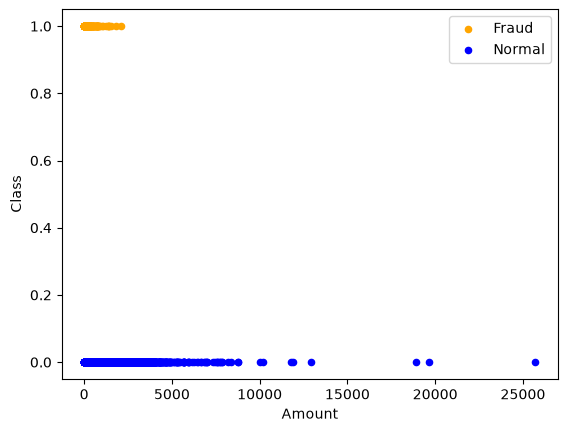

In [7]:
ax = frauds.plot.scatter(x="Amount", y="Class", color="Orange", label="Fraud")
non_frauds.plot.scatter(x="Amount", y="Class", color="Blue", label="Normal", ax=ax)
plt.show()

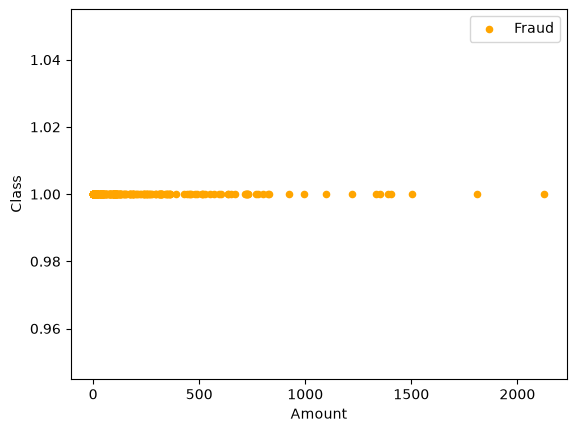

In [8]:
bx = frauds.plot.scatter(x="Amount", y="Class", color="Orange", label="Fraud")
plt.show()

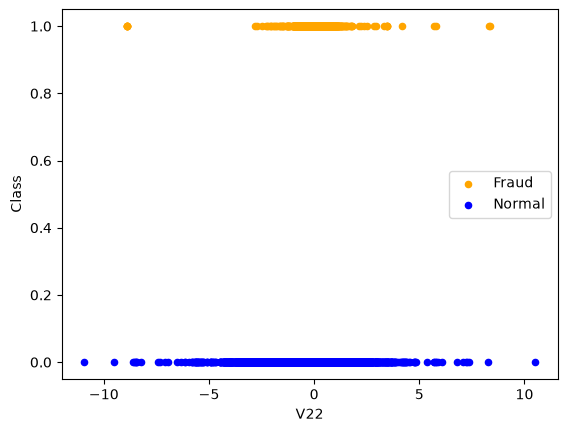

In [9]:
ax = frauds.plot.scatter(x="V22", y="Class", color="Orange", label="Fraud")
non_frauds.plot.scatter(x="V22", y="Class", color="Blue", label="Normal", ax=ax)
plt.show()

## Logistic Regression

In [10]:
X = df.iloc[:, :-1]
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.35, random_state=42, stratify=y
)

print("Ukuran X dan y secara berurutan adalah:", len(X), len(y))
print(
    "Ukuran data latih (training) dan data uji (testing) secara berurutan:",
    len(X_train), len(y_train), "|", len(X_test), len(y_test),
)
print(f"Total fraud: {len(y.loc[y == 1])} ({y.mean():.4%})")
print(f"Fraud di y_train: {len(y_train.loc[y_train == 1])} ({y_train.mean():.4%})")
print(f"Fraud di y_test: {len(y_test.loc[y_test == 1])} ({y_test.mean():.4%})")

Ukuran X dan y secara berurutan adalah: 284807 284807
Ukuran data latih (training) dan data uji (testing) secara berurutan: 185124 185124 | 99683 99683
Total fraud: 492 (0.1727%)
Fraud di y_train: 320 (0.1729%)
Fraud di y_test: 172 (0.1725%)


In [11]:
model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "clf",
        LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

model.fit(X_train, y_train)
print("Score (akurasi) pada data uji:", model.score(X_test, y_test))

Score (akurasi) pada data uji: 0.9770873669532418


In [12]:
y_predicted = np.array(model.predict(X_test))
y_prob = model.predict_proba(X_test)[:, 1]
y_right = np.array(y_test)

Accuracy: 0.9771

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     99511
       Fraud       0.06      0.90      0.12       172

    accuracy                           0.98     99683
   macro avg       0.53      0.94      0.55     99683
weighted avg       1.00      0.98      0.99     99683



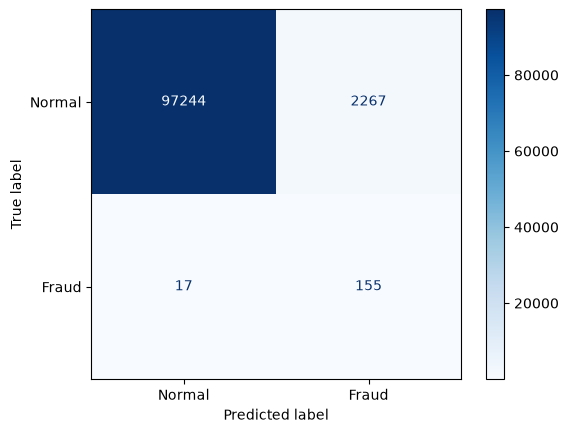

False Negative Rate (FNR): 0.0988
ROC-AUC: 0.9771
PR-AUC (Average Precision): 0.7265


In [13]:
accuracy = accuracy_score(y_right, y_predicted)
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_right, y_predicted, target_names=["Normal", "Fraud"]))

cm = confusion_matrix(y_right, y_predicted)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])
disp.plot(cmap="Blues")
plt.show()

tn, fp, fn, tp = cm.ravel()
fnr = fn / (fn + tp)
print(f"False Negative Rate (FNR): {fnr:.4f}")

roc_auc = roc_auc_score(y_right, y_prob)
pr_auc = average_precision_score(y_right, y_prob)
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")

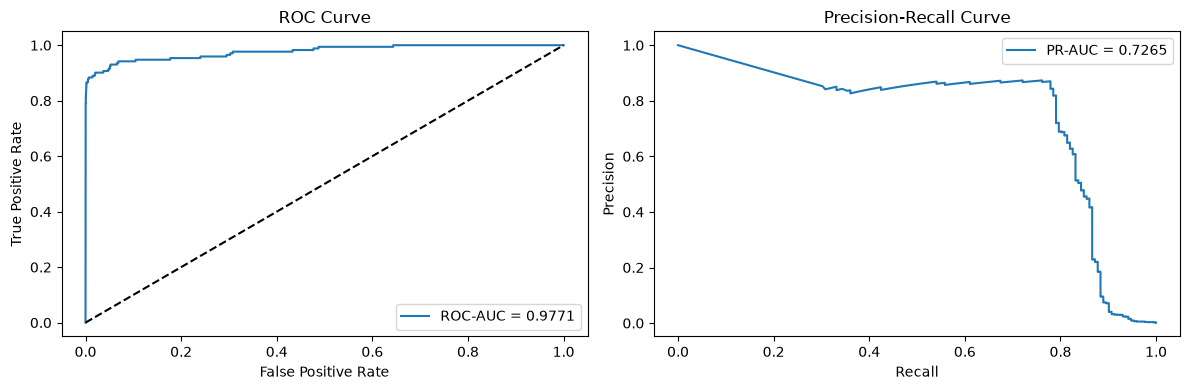

In [14]:
fpr, tpr, _ = roc_curve(y_right, y_prob)
precision, recall, _ = precision_recall_curve(y_right, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

axes[1].plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

## Kesimpulan

- Model **Logistic Regression** dilatih dengan pipeline `StandardScaler` + `class_weight='balanced'` untuk menangani data yang sangat imbalance (±0,17% fraud).
- Pada data imbalance, **accuracy saja tidak cukup**; metrik **recall fraud**, **FNR**, **ROC-AUC**, dan **PR-AUC** lebih informatif untuk menilai kemampuan model menemukan kasus fraud.
- `stratify=y` pada `train_test_split` menjaga proporsi fraud tetap sama di data latih dan data uji, serta `random_state=42` membuat hasil reproduksibel.
- Eksperimen lanjutan: bandingkan dengan model lain (Random Forest, XGBoost, dll.) dan lakukan hyperparameter tuning.